# 架构

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np


# ==========================================
# 1. Patch Embedding：把图像切分成 Patch 并嵌入
# ==========================================
class PatchEmbedding(nn.Module):
    """
    将 (B, C, H, W) 的图像转化为 (B, num_patches, embed_dim) 的序列
    使用 2D 卷积一次性完成切分 + 线性映射，等价于 unfold + linear
    """
    def __init__(self, img_size=224, patch_size=16, in_channels=3, embed_dim=768):
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.num_patches = (img_size // patch_size) ** 2  # 14x14 = 196

        # 用卷积实现 Patch 投影，卷积核大小=步长=patch_size
        self.proj = nn.Conv2d(
            in_channels, embed_dim,
            kernel_size=patch_size, stride=patch_size
        )

    def forward(self, x):
        # x: (B, 3, 224, 224)
        x = self.proj(x)          # (B, 768, 14, 14)
        x = x.flatten(2)          # (B, 768, 196) # 把第 2 维及以后展平
        x = x.transpose(1, 2)     # (B, 196, 768) # 交换第 1、2 维，转换成 Transformer 要求的输入格式：`(批次, 序列长度, 特征维度)`
        return x


# ==========================================
# 2. Multi-Head Self-Attention
# ==========================================
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim=768, num_heads=12, dropout=0.):
        super().__init__()
        self.num_heads = num_heads # 注意力头的数量
        self.head_dim = embed_dim // num_heads  # 每个头的维度，这里是 768 ÷ 12 = 64，每个头只处理 64 维
        self.scale = self.head_dim ** -0.5      # 缩放因子，等于 1/√d_k

        # QKV 一次性线性映射
        self.qkv = nn.Linear(embed_dim, embed_dim * 3) # 输出维度是 3 倍嵌入维度，比写三个 Linear 层更高效
        self.attn_drop = nn.Dropout(dropout)
        self.proj = nn.Linear(embed_dim, embed_dim) # 多头结果拼接后，再做一次线性映射，融合多头信息
        self.proj_drop = nn.Dropout(dropout)

    def forward(self, x):
        B, N, C = x.shape  # (batch, seq_len, embed_dim)

        # 生成 Q, K, V 并拆分为多头
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim) # 3 对应 Q/K/V，12 个头，每个头 64 维
        qkv = qkv.permute(2, 0, 3, 1, 4)  # (3, B, heads, N, head_dim)，作用是调整维度顺序 → `(3, B, 12, N, 64)`
        q, k, v = qkv[0], qkv[1], qkv[2]

        # 计算注意力得分
        attn = (q @ k.transpose(-2, -1)) * self.scale  # (B, heads, N, N)，得到注意力得分矩阵
        attn = attn.softmax(dim=-1)
        attn = self.attn_drop(attn)

        # 加权求和
        x = (attn @ v).transpose(1, 2).reshape(B, N, C)  # 拼接多头
        x = self.proj(x)
        x = self.proj_drop(x)
        return x


# ==========================================
# 3. MLP（Feed Forward Network）
# ==========================================
# 结构是「线性升维 → GELU 激活 → 线性降维 → Dropout」
class MLP(nn.Module):
    def __init__(self, embed_dim=768, mlp_ratio=4.0, dropout=0.):
        super().__init__()
        hidden_dim = int(embed_dim * mlp_ratio) # 隐藏层维度是输入的 4 倍
        self.fc1 = nn.Linear(embed_dim, hidden_dim)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden_dim, embed_dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.drop(x)
        x = self.fc2(x)
        x = self.drop(x)
        return x


# ==========================================
# 4. Transformer Encoder Block
# ==========================================
# 由「注意力 + 残差 + 层归一化 + MLP + 残差 + 层归一化」组成
class TransformerBlock(nn.Module):
    """
    标准结构：LN -> Attention -> 残差 -> LN -> MLP -> 残差
    """
    def __init__(self, embed_dim=768, num_heads=12, mlp_ratio=4.0, dropout=0.):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = MultiHeadAttention(embed_dim, num_heads, dropout)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = MLP(embed_dim, mlp_ratio, dropout)

    def forward(self, x):
        x = x + self.attn(self.norm1(x))   # 预归一化 + 残差
        x = x + self.mlp(self.norm2(x))
        return x


# ==========================================
# 5. 完整 Vision Transformer
# ==========================================
# 加入 cls 分类令牌、位置编码，最后接分类头，构成完整的图像分类模型。
class VisionTransformer(nn.Module):
    def __init__(
        self,
        img_size=224,
        patch_size=16,
        in_channels=3,
        num_classes=1000,
        embed_dim=768,
        depth=12,
        num_heads=12,
        mlp_ratio=4.0,
        dropout=0.
    ):
        super().__init__()

        # Patch Embedding
        self.patch_embed = PatchEmbedding(img_size, patch_size, in_channels, embed_dim)
        num_patches = self.patch_embed.num_patches

        # Class Token：可学习的分类向量
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim)) # nn.Parameter是把一个普通张量标记为模型的可训练权重，让它能被优化器更新、能参与反向传播计算梯度。

        # 可学习的位置编码（论文用可学习，不用正弦）
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        self.pos_drop = nn.Dropout(dropout)

        # Transformer Encoder 堆叠
        self.blocks = nn.ModuleList([
            TransformerBlock(embed_dim, num_heads, mlp_ratio, dropout)
            for _ in range(depth)
        ])

        # 最后的分类头
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

        # 初始化权重
        self._init_weights()

    def _init_weights(self):
        # 按论文风格初始化
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        self.apply(self._init_module)

    def _init_module(self, m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)

    def forward(self, x):
        B = x.shape[0]

        # 1. Patch Embedding
        x = self.patch_embed(x)  # (B, 196, 768)

        # 2. 拼接 cls token
        cls_tokens = self.cls_token.expand(B, -1, -1)  # (B, 1, 768)
        x = torch.cat((cls_tokens, x), dim=1)          # (B, 197, 768)

        # 3. 加上位置编码
        x = x + self.pos_embed
        x = self.pos_drop(x)

        # 4. 通过所有 Transformer Block
        for block in self.blocks:
            x = block(x)

        # 5. 取出 cls token 做分类
        x = self.norm(x)
        cls_out = x[:, 0]  # 取序列第一个位置
        logits = self.head(cls_out)

        return logits


# ==========================================
# 6. 快速验证：前向传播测试
# ==========================================
if __name__ == "__main__":
    # 构建 ViT-Base 配置
    model = VisionTransformer(
        img_size=224,
        patch_size=16,
        embed_dim=768,
        depth=12,
        num_heads=12,
        num_classes=1000
    )

    # 打印参数量
    total_params = sum(p.numel() for p in model.parameters())
    print(f"ViT-Base 总参数量: {total_params / 1e6:.2f} M")

    # 测试前向传播
    dummy_img = torch.randn(2, 3, 224, 224)  # batch=2, 3通道, 224x224
    output = model(dummy_img)
    print(f"输入形状: {dummy_img.shape}")
    print(f"输出形状: {output.shape}")  # 应为 (2, 1000)


ViT-Base 总参数量: 86.57 M
输入形状: torch.Size([2, 3, 224, 224])
输出形状: torch.Size([2, 1000])


---

# 实战


训练集大小: 50000 张
测试集大小: 10000 张

模型总参数量: 0.55 M

开始训练...


Epoch [01/50] 训练Loss: 1.8512 | 训练Acc: 30.49% | 测试Loss: 1.6717 | 测试Acc: 38.55% | LR: 0.000300


Epoch [02/50] 训练Loss: 1.5623 | 训练Acc: 42.77% | 测试Loss: 1.4335 | 测试Acc: 48.26% | LR: 0.000299


Epoch [03/50] 训练Loss: 1.4099 | 训练Acc: 48.79% | 测试Loss: 1.3427 | 测试Acc: 51.71% | LR: 0.000297


Epoch [04/50] 训练Loss: 1.3221 | 训练Acc: 52.12% | 测试Loss: 1.2395 | 测试Acc: 55.50% | LR: 0.000295


...

Epoch [46/50] 训练Loss: 0.6397 | 训练Acc: 77.30% | 测试Loss: 0.6568 | 测试Acc: 77.29% | LR: 0.000005


Epoch [47/50] 训练Loss: 0.6384 | 训练Acc: 77.32% | 测试Loss: 0.6562 | 测试Acc: 77.13% | LR: 0.000003


Epoch [48/50] 训练Loss: 0.6374 | 训练Acc: 77.33% | 测试Loss: 0.6568 | 测试Acc: 77.33% | LR: 0.000001


Epoch [49/50] 训练Loss: 0.6394 | 训练Acc: 77.35% | 测试Loss: 0.6557 | 测试Acc: 77.31% | LR: 0.000000


Epoch [50/50] 训练Loss: 0.6434 | 训练Acc: 77.09% | 测试Loss: 0.6549 | 测试Acc: 77.34% | LR: 0.000000

模型权重已保存为: mini_vit_cifar10.pth
训练曲线已保存为: vit_training_curve.png


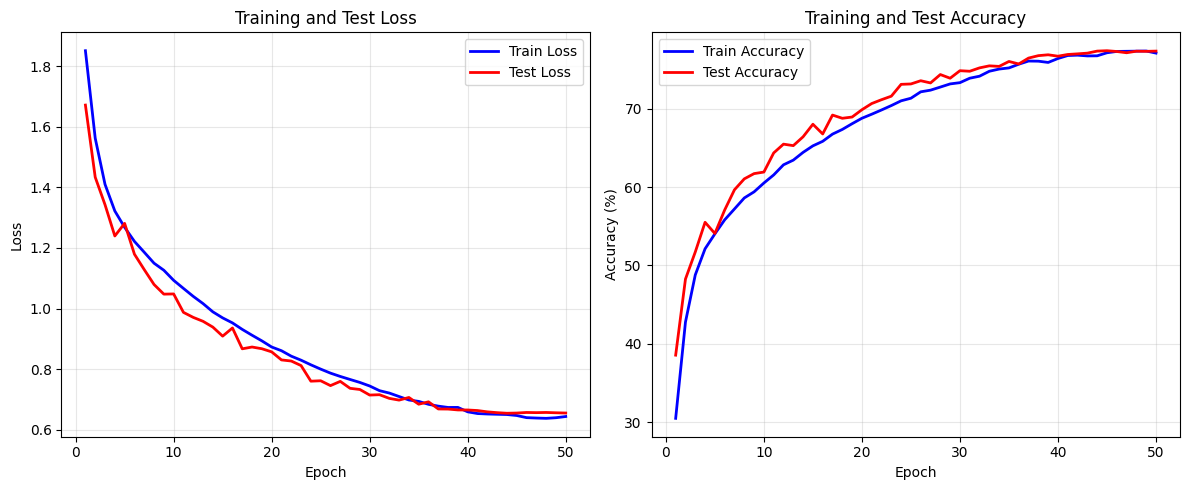


单张图片推理演示


/tmp/ipykernel_695/3434782341.py:300: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_695/3434782341.py:300: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_695/3434782341.py:300: UserWarning: Glyph 26631 (\N{CJK UNIFIED IDEOGRAPH-6807}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_695/3434782341.py:300: UserWarning: Glyph 31614 (\N{CJK UNIFIED IDEOGRAPH-7B7E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_695/3434782341.py:300: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_695/3434782341.py:300: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_695/3434782341.py:301: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}

单图推理结果已保存为: single_inference.png


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 26631 (\N{CJK UNIFIED IDEOGRAPH-6807}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 31614 (\N{CJK UNIFIED IDEOGRAPH-7B7E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  fig.canvas

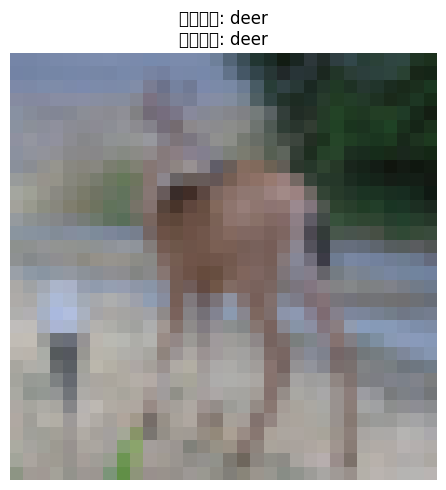


注意力权重可视化


/tmp/ipykernel_695/3434782341.py:361: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_695/3434782341.py:361: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_695/3434782341.py:361: UserWarning: Glyph 27880 (\N{CJK UNIFIED IDEOGRAPH-6CE8}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_695/3434782341.py:361: UserWarning: Glyph 24847 (\N{CJK UNIFIED IDEOGRAPH-610F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_695/3434782341.py:361: UserWarning: Glyph 21147 (\N{CJK UNIFIED IDEOGRAPH-529B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_695/3434782341.py:361: UserWarning: Glyph 28909 (\N{CJK UNIFIED IDEOGRAPH-70ED}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_695/3434782341.py:361: UserWarning: Glyph 21472 (\N{CJK UNIFIED IDEOGRAPH-53E0}

注意力可视化结果已保存为: attention_visualization.png


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 27880 (\N{CJK UNIFIED IDEOGRAPH-6CE8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 24847 (\N{CJK UNIFIED IDEOGRAPH-610F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 21147 (\N{CJK UNIFIED IDEOGRAPH-529B}) missing from font(s) DejaVu Sans.
  fig.canvas

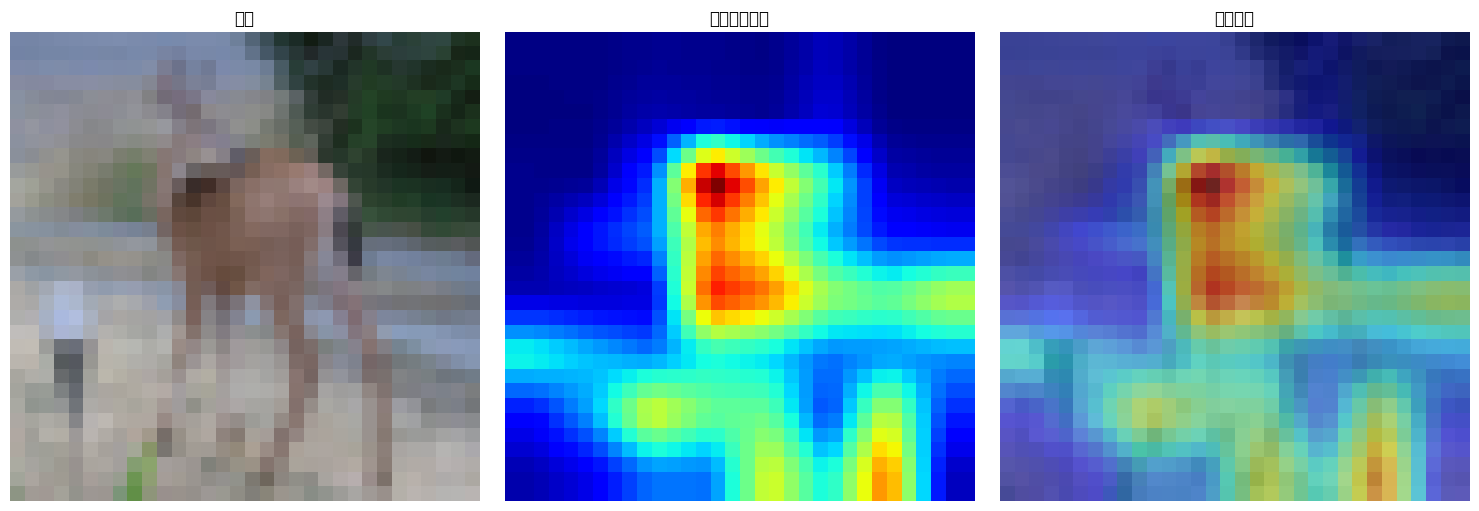

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

# ======================
# 超参数配置
# ======================
BATCH_SIZE = 128
EPOCHS = 50               # 增加到50轮保证收敛
LR = 3e-4
IMG_SIZE = 32
PATCH_SIZE = 4
EMBED_DIM = 128
DEPTH = 4
NUM_HEADS = 4
MLP_RATIO = 2.0
NUM_CLASSES = 10
DROPOUT = 0.1
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# CIFAR-10 类别名称
CLASSES = ('plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')
# 归一化参数
MEAN = [0.4914, 0.4822, 0.4465]
STD = [0.2470, 0.2435, 0.2616]


# ======================
# 1. 数据集与数据加载
# ======================
def get_dataloaders():
    train_transform = transforms.Compose([
        transforms.RandomCrop(IMG_SIZE, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD)
    ])

    test_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD)
    ])

    train_dataset = datasets.CIFAR10(
        root='./data', train=True, download=True, transform=train_transform
    )
    test_dataset = datasets.CIFAR10(
        root='./data', train=False, download=True, transform=test_transform
    )

    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2
    )
    test_loader = DataLoader(
        test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2
    )

    return train_loader, test_loader, test_dataset


# ======================
# 2. Vision Transformer 模型（支持返回注意力权重）
# ======================
class PatchEmbedding(nn.Module):
    def __init__(self, img_size=32, patch_size=4, in_channels=3, embed_dim=128):
        super().__init__()
        self.num_patches = (img_size // patch_size) ** 2
        self.proj = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        x = self.proj(x)
        x = x.flatten(2)
        x = x.transpose(1, 2)
        return x


class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim=128, num_heads=4, dropout=0.):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.scale = self.head_dim ** -0.5

        self.qkv = nn.Linear(embed_dim, embed_dim * 3)
        self.attn_drop = nn.Dropout(dropout)
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.proj_drop = nn.Dropout(dropout)

    def forward(self, x, return_attention=False):
        B, N, C = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim)
        qkv = qkv.permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]

        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)
        attn = self.attn_drop(attn)

        x = (attn @ v).transpose(1, 2).reshape(B, N, C)
        x = self.proj(x)
        x = self.proj_drop(x)

        if return_attention:
            return x, attn
        return x


class MLP(nn.Module):
    def __init__(self, embed_dim=128, mlp_ratio=2.0, dropout=0.):
        super().__init__()
        hidden_dim = int(embed_dim * mlp_ratio)
        self.fc1 = nn.Linear(embed_dim, hidden_dim)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden_dim, embed_dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.drop(x)
        x = self.fc2(x)
        x = self.drop(x)
        return x


class TransformerBlock(nn.Module):
    def __init__(self, embed_dim=128, num_heads=4, mlp_ratio=2.0, dropout=0.):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = MultiHeadAttention(embed_dim, num_heads, dropout)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = MLP(embed_dim, mlp_ratio, dropout)

    def forward(self, x, return_attention=False):
        if return_attention:
            attn_out, attn = self.attn(self.norm1(x), return_attention=True)
            x = x + attn_out
            x = x + self.mlp(self.norm2(x))
            return x, attn
        else:
            x = x + self.attn(self.norm1(x))
            x = x + self.mlp(self.norm2(x))
            return x


class VisionTransformer(nn.Module):
    def __init__(
        self,
        img_size=32,
        patch_size=4,
        in_channels=3,
        num_classes=10,
        embed_dim=128,
        depth=4,
        num_heads=4,
        mlp_ratio=2.0,
        dropout=0.1
    ):
        super().__init__()
        self.patch_embed = PatchEmbedding(img_size, patch_size, in_channels, embed_dim)
        num_patches = self.patch_embed.num_patches
        self.num_patches = num_patches
        self.patch_size = patch_size

        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        self.pos_drop = nn.Dropout(dropout)

        self.blocks = nn.ModuleList([
            TransformerBlock(embed_dim, num_heads, mlp_ratio, dropout)
            for _ in range(depth)
        ])

        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

        self._init_weights()

    def _init_weights(self):
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        self.apply(self._init_module)

    def _init_module(self, m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)

    def forward(self, x, return_attention=False):
        B = x.shape[0]
        x = self.patch_embed(x)

        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)

        x = x + self.pos_embed
        x = self.pos_drop(x)

        attn_weights = []
        for block in self.blocks:
            if return_attention:
                x, attn = block(x, return_attention=True)
                attn_weights.append(attn)
            else:
                x = block(x)

        x = self.norm(x)
        cls_out = x[:, 0]
        logits = self.head(cls_out)

        if return_attention:
            return logits, attn_weights
        return logits


# ======================
# 3. 训练与测试函数
# ======================
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(loader, desc="Training", leave=False):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    avg_loss = total_loss / total
    accuracy = 100. * correct / total
    return avg_loss, accuracy


def test(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Testing", leave=False):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    avg_loss = total_loss / total
    accuracy = 100. * correct / total
    return avg_loss, accuracy


# ======================
# 4. 单张图片推理演示
# ======================
def inference_single_image(model, dataset, device, img_idx=0):
    model.eval()
    # 取出单张图片和标签
    img_tensor, true_label = dataset[img_idx]
    img_tensor = img_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(img_tensor)
        _, pred_label = outputs.max(1)
        pred_label = pred_label.item()

    # 反归一化，还原图片用于显示
    img_np = img_tensor.squeeze().cpu().numpy().transpose(1, 2, 0)
    img_np = img_np * np.array(STD) + np.array(MEAN)
    img_np = np.clip(img_np, 0, 1)

    # 绘图
    plt.figure(figsize=(5, 5))
    plt.imshow(img_np)
    plt.title(f"真实标签: {CLASSES[true_label]}\n预测标签: {CLASSES[pred_label]}", fontsize=12)
    plt.axis('off')
    plt.tight_layout()
    plt.savefig('single_inference.png', dpi=300, bbox_inches='tight')
    print("单图推理结果已保存为: single_inference.png")
    plt.show()

    return img_tensor, true_label, pred_label


# ======================
# 5. 注意力权重可视化
# ======================
def visualize_attention(model, img_tensor, device):
    model.eval()
    with torch.no_grad():
        _, attn_weights = model(img_tensor, return_attention=True)

    # 取最后一层 Transformer 的注意力
    last_attn = attn_weights[-1]  # shape: (1, num_heads, N, N)
    last_attn = last_attn.squeeze(0).cpu().numpy()  # (num_heads, N, N)

    # 取 cls token 对所有 patch 的注意力，多头取平均
    cls_attn = last_attn[:, 0, 1:]  # 去掉cls自身，shape: (num_heads, num_patches)
    cls_attn = cls_attn.mean(axis=0)  # 多头平均

    # reshape 成二维网格
    patch_num = int(np.sqrt(model.num_patches))
    attn_map = cls_attn.reshape(patch_num, patch_num)

    # 上采样到原图大小
    attn_map = torch.tensor(attn_map).unsqueeze(0).unsqueeze(0)
    attn_map = nn.functional.interpolate(
        attn_map, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False
    )
    attn_map = attn_map.squeeze().numpy()
    # 归一化到0-1
    attn_map = (attn_map - attn_map.min()) / (attn_map.max() - attn_map.min())

    # 还原原图
    img_np = img_tensor.squeeze().cpu().numpy().transpose(1, 2, 0)
    img_np = img_np * np.array(STD) + np.array(MEAN)
    img_np = np.clip(img_np, 0, 1)

    # 绘图：原图 + 热力图 + 叠加图
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img_np)
    plt.title("原图", fontsize=12)
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(attn_map, cmap='jet')
    plt.title("注意力热力图", fontsize=12)
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(img_np)
    plt.imshow(attn_map, cmap='jet', alpha=0.5)  # 半透明叠加
    plt.title("叠加效果", fontsize=12)
    plt.axis('off')

    plt.tight_layout()
    plt.savefig('attention_visualization.png', dpi=300, bbox_inches='tight')
    print("注意力可视化结果已保存为: attention_visualization.png")
    plt.show()


# ======================
# 6. 主程序
# ======================
def main():
    # 加载数据
    train_loader, test_loader, test_dataset = get_dataloaders()
    print(f"\n训练集大小: {len(train_loader.dataset)} 张")
    print(f"测试集大小: {len(test_loader.dataset)} 张")

    # 初始化模型
    model = VisionTransformer(
        img_size=IMG_SIZE,
        patch_size=PATCH_SIZE,
        embed_dim=EMBED_DIM,
        depth=DEPTH,
        num_heads=NUM_HEADS,
        mlp_ratio=MLP_RATIO,
        num_classes=NUM_CLASSES,
        dropout=DROPOUT
    ).to(DEVICE)

    total_params = sum(p.numel() for p in model.parameters())
    print(f"\n模型总参数量: {total_params / 1e6:.2f} M")

    # 损失函数 + 优化器 + 学习率调度器
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

    # 记录日志
    train_loss_list, train_acc_list = [], []
    test_loss_list, test_acc_list = [], []

    # 开始训练
    print("\n" + "="*60)
    print("开始训练...")
    print("="*60)
    for epoch in range(EPOCHS):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
        test_loss, test_acc = test(model, test_loader, criterion, DEVICE)
        scheduler.step()  # 更新学习率

        train_loss_list.append(train_loss)
        train_acc_list.append(train_acc)
        test_loss_list.append(test_loss)
        test_acc_list.append(test_acc)

        print(f"Epoch [{epoch+1:02d}/{EPOCHS}] "
              f"训练Loss: {train_loss:.4f} | 训练Acc: {train_acc:.2f}% | "
              f"测试Loss: {test_loss:.4f} | 测试Acc: {test_acc:.2f}% | "
              f"LR: {scheduler.get_last_lr()[0]:.6f}")

    # 保存模型
    torch.save(model.state_dict(), "mini_vit_cifar10.pth")
    print("\n模型权重已保存为: mini_vit_cifar10.pth")

    # 绘制训练曲线
    epochs_range = range(1, EPOCHS + 1)
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, train_loss_list, 'b-', linewidth=2, label='Train Loss')
    plt.plot(epochs_range, test_loss_list, 'r-', linewidth=2, label='Test Loss')
    plt.title('Training and Test Loss', fontsize=12)
    plt.xlabel('Epoch', fontsize=10)
    plt.ylabel('Loss', fontsize=10)
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, train_acc_list, 'b-', linewidth=2, label='Train Accuracy')
    plt.plot(epochs_range, test_acc_list, 'r-', linewidth=2, label='Test Accuracy')
    plt.title('Training and Test Accuracy', fontsize=12)
    plt.xlabel('Epoch', fontsize=10)
    plt.ylabel('Accuracy (%)', fontsize=10)
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('vit_training_curve.png', dpi=300, bbox_inches='tight')
    print("训练曲线已保存为: vit_training_curve.png")
    plt.show()

    # ========== 新增：单图推理 + 注意力可视化 ==========
    print("\n" + "="*60)
    print("单张图片推理演示")
    print("="*60)
    # 选测试集第100张图片（可随意修改索引）
    img_tensor, true_label, pred_label = inference_single_image(model, test_dataset, DEVICE, img_idx=100)

    print("\n" + "="*60)
    print("注意力权重可视化")
    print("="*60)
    visualize_attention(model, img_tensor, DEVICE)


if __name__ == "__main__":
    main()
